# Workload-Aware Cloud Storage Tiering for Cost and Latency Optimization
### Research-strengthened Google Colab notebook — v4

**Goal:** compare static-hot, threshold, workload-aware, and a new **SLA-aware cost policy** under stable and shifting workloads. The SLA-aware policy makes decisions from prior-window demand and compares expected per-interval costs while restricting assignments to tiers whose modeled latency is within the configured 150 ms target.

**Run in Google Colab:** upload this notebook and choose **Runtime → Run all**.

**Research integrity:** this version improves the experiment design, but synthetic workload and illustrative tier prices remain assumptions. It is not evidence of live-cloud performance. Use official provider prices and a licensed real trace before making external-validity claims.


## Project map

1. Reproducible setup and explicit assumptions
2. Configurable tier cost/latency model
3. Stable and shifted synthetic workloads
4. Leakage-aware historical features
5. Four policies, including an SLA-aware cost policy
6. Interval simulation and cost-component accounting
7. Repeated-seed comparisons and SLA feasibility reporting
8. Plots and sensitivity analysis
9. Ablation study
10. Structural, causality, and SLA-policy tests
11. Export CSVs, configuration, and ZIP
12. Final research-validity checklist

**Interpretation rule:** a policy is not declared best merely because it wins one metric. Read total cost, p95 latency, SLA feasibility, migration count, and moved GB together.


## 1. Setup and configuration

In [13]:
import sys, os, json, math, random, platform, zipfile, warnings
from pathlib import Path
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
OUTPUT_DIR = Path("/content/cloud_tiering_project")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Experiment configuration
N_OBJECTS = 500
N_EVENTS = 30000
SIMULATED_DAYS = 30
DECISION_INTERVAL_EVENTS = 2500
WINDOW_EVENTS = 5000
RANDOM_SEEDS = [11, 22, 33, 44, 55]

np.random.seed(SEED)
random.seed(SEED)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Output directory:", OUTPUT_DIR)

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
NumPy: 2.1.3
pandas: 2.2.3
Output directory: /content/cloud_tiering_project


## 2. Storage tiers and cost model

Edit this configuration only after choosing a pricing source. The values below are **illustrative placeholders** and must not be presented as provider quotes.

Modelled components:
- capacity cost prorated by simulated time
- request cost
- retrieval cost per GB read
- migration cost per GB moved
- estimated tier latency per read

The initial simulation assumes one provider, one region, no replication, no minimum storage-duration penalties, and no egress cost except where explicitly added to the migration/transfer term. These assumptions must be stated and refined for the final study.

In [14]:
TIERS = {
    "hot": {
        "storage_per_gb_month": 0.020,
        "read_latency_ms": 20.0,
        "retrieval_per_gb": 0.000,
        "request_per_1000": 0.004,
    },
    "cool": {
        "storage_per_gb_month": 0.010,
        "read_latency_ms": 100.0,
        "retrieval_per_gb": 0.010,
        "request_per_1000": 0.010,
    },
    "cold": {
        "storage_per_gb_month": 0.004,
        "read_latency_ms": 600.0,
        "retrieval_per_gb": 0.020,
        "request_per_1000": 0.030,
    },
}
TIER_ORDER = {"hot": 0, "cool": 1, "cold": 2}

# Illustrative migration charge; replace/justify using the chosen pricing model.
MIGRATION_COST_PER_GB = 0.005
# Assumed transfer charge per GB moved; 0 by default to avoid double counting
# until the chosen provider's transfer model is specified.
TRANSFER_COST_PER_GB = 0.0

# Latency is a tier-level estimate in this simulation, not live-provider measurement.
LATENCY_CONSTRAINT_MS = 150.0

pd.DataFrame(TIERS).T

,storage_per_gb_month,read_latency_ms,retrieval_per_gb,request_per_1000
hot,0.020,20.0,0.00,0.004
cool,0.010,100.0,0.01,0.010
cold,0.004,600.0,0.02,0.030


## 3. Workload generator

The generator creates read events for objects with fixed sizes. The **stable** scenario retains the same popularity ranking. The **shift** scenario changes the popularity distribution halfway through the trace. Each seed generates a reproducible trace.

This is synthetic workload data. For stronger external validity, replace or supplement it with a documented public trace and preserve the trace's licensing and usage requirements.

In [15]:
def generate_workload(
    scenario="shift",
    n_objects=N_OBJECTS,
    n_events=N_EVENTS,
    simulated_days=SIMULATED_DAYS,
    seed=SEED,
):
    if scenario not in {"stable", "shift"}:
        raise ValueError("scenario must be 'stable' or 'shift'")
    rng = np.random.default_rng(seed)
    object_ids = np.array([f"obj_{i:05d}" for i in range(n_objects)])
    sizes = np.clip(rng.lognormal(mean=-1.2, sigma=1.0, size=n_objects), 0.01, 20.0)

    ranks = np.arange(1, n_objects + 1, dtype=float)
    popularity_a = 1.0 / np.power(ranks, 1.15)
    popularity_a /= popularity_a.sum()

    # In shift scenario, a random permutation creates a different set of popular objects.
    perm = rng.permutation(n_objects)
    popularity_b = np.zeros(n_objects)
    popularity_b[perm] = popularity_a

    split = n_events // 2
    if scenario == "stable":
        chosen = rng.choice(n_objects, size=n_events, p=popularity_a)
    else:
        first = rng.choice(n_objects, size=split, p=popularity_a)
        second = rng.choice(n_objects, size=n_events - split, p=popularity_b)
        chosen = np.concatenate([first, second])

    # Simulated timestamps are ordered across the full time horizon.
    elapsed_seconds = np.linspace(0, simulated_days * 24 * 3600, n_events, endpoint=False)
    # Add small deterministic jitter while preserving event order.
    timestamps = pd.to_datetime(elapsed_seconds, unit="s", origin="unix")
    df = pd.DataFrame({
        "event_index": np.arange(n_events, dtype=int),
        "timestamp": timestamps,
        "object_id": object_ids[chosen],
        "object_size_gb": sizes[chosen],
        "operation": "read",
        "scenario": scenario,
        "phase": np.where(np.arange(n_events) < split, "pre_shift", "post_shift") if scenario == "shift" else "stable",
    })
    return df

demo_trace = generate_workload("shift", seed=SEED)
print("Events:", len(demo_trace))
print("Unique objects:", demo_trace["object_id"].nunique())
display(demo_trace.head())
display(demo_trace.groupby(["scenario", "phase"]).size().rename("events").to_frame())

Events: 30000
Unique objects: 500


,event_index,timestamp,object_id,object_size_gb,operation,scenario,phase
0,0,1970-01-01 00:00:00.000,obj_00000,0.408492,read,shift,pre_shift
1,1,1970-01-01 00:01:26.400,obj_00003,0.771487,read,shift,pre_shift
2,2,1970-01-01 00:02:52.800,obj_00003,0.771487,read,shift,pre_shift
3,3,1970-01-01 00:04:19.200,obj_00000,0.408492,read,shift,pre_shift
4,4,1970-01-01 00:05:45.600,obj_00000,0.408492,read,shift,pre_shift


events
scenario phase             
shift    post_shift   15000
         pre_shift    15000

## 4. Input validation and feature extraction

Features are computed only from events before the current decision boundary:
- recent access count in a fixed event window
- event recency (number of events since last access)
- object size

Objects absent from the current window remain in the object table with zero recent accesses and a large recency value. No future events are used for a decision.

In [16]:
def validate_trace(trace):
    required = {"event_index", "timestamp", "object_id", "object_size_gb", "operation"}
    missing = required - set(trace.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    if trace.empty:
        raise ValueError("Trace is empty")
    if trace["object_id"].isna().any():
        raise ValueError("object_id contains missing values")
    if (trace["object_size_gb"] <= 0).any():
        raise ValueError("object_size_gb must be positive")
    if not trace["event_index"].is_monotonic_increasing:
        raise ValueError("event_index must be sorted")
    if not set(trace["operation"].unique()).issubset({"read"}):
        raise ValueError("This first implementation models read events only")
    return True

def extract_features(trace, decision_end, window_events=WINDOW_EVENTS):
    # Only rows strictly before decision_end are visible to the policy.
    history = trace.iloc[max(0, decision_end - window_events):decision_end]
    object_sizes = trace.groupby("object_id")["object_size_gb"].first()
    all_ids = object_sizes.index
    if history.empty:
        return pd.DataFrame({
            "object_id": all_ids,
            "object_size_gb": object_sizes.values,
            "recent_reads": 0,
            "recency_events": decision_end,
        })

    counts = history.groupby("object_id").size().rename("recent_reads")
    last_seen = history.groupby("object_id")["event_index"].max().rename("last_event")
    feats = pd.concat([counts, last_seen], axis=1).reindex(all_ids)
    feats["recent_reads"] = feats["recent_reads"].fillna(0).astype(int)
    feats["recency_events"] = decision_end - feats["last_event"].fillna(-1)
    feats["object_size_gb"] = object_sizes
    feats = feats.drop(columns=["last_event"]).reset_index(names="object_id")
    return feats[["object_id", "object_size_gb", "recent_reads", "recency_events"]]

assert validate_trace(demo_trace)
display(extract_features(demo_trace, decision_end=5000).sort_values("recent_reads", ascending=False).head(10))

,object_id,object_size_gb,recent_reads,recency_events
0,obj_00000,0.408492,1107,7.0
1,obj_00001,0.106460,507,3.0
2,obj_00002,0.637916,305,19.0
3,obj_00003,0.771487,209,44.0
4,obj_00004,0.042808,190,200.0
5,obj_00005,0.081906,138,9.0
7,obj_00007,0.219535,114,27.0
6,obj_00006,0.342269,106,127.0
8,obj_00008,0.296176,83,56.0
9,obj_00009,0.128344,80,26.0


## 5. Placement policies

- **Static-hot:** performance-first baseline.
- **Threshold:** fixed access-count/recency rules.
- **Workload-aware:** interpretable score with hysteresis.
- **SLA-aware cost:** estimates next-interval read demand from the preceding window, evaluates the expected storage + retrieval + request cost of hot versus cool, and includes migration cost when switching. It excludes cold assignments because the modeled cold latency (600 ms) exceeds the 150 ms SLA; therefore its policy assignments are SLA-feasible under the stated tier-level latency assumptions.

The SLA-aware policy is a **candidate baseline**, not a novelty claim. It is intentionally transparent and should be compared with published algorithms after their assumptions are reviewed.


In [17]:
def static_policy(features, current_tiers=None, **kwargs):
    return {oid: "hot" for oid in features["object_id"]}

def threshold_policy(features, current_tiers=None, **kwargs):
    out = {}
    for r in features.itertuples(index=False):
        if r.recent_reads >= 30 and r.recency_events <= 1000:
            tier = "hot"
        elif r.recent_reads >= 5 and r.recency_events <= 3000:
            tier = "cool"
        else:
            tier = "cold"
        out[r.object_id] = tier
    return out

def workload_aware_policy(features, current_tiers=None, hysteresis=True, **kwargs):
    current_tiers = current_tiers or {}
    out = {}
    for r in features.itertuples(index=False):
        score = np.log1p(r.recent_reads) - 0.002 * np.log1p(r.recency_events)
        if score >= 2.8:
            proposed = "hot"
        elif score >= 1.1:
            proposed = "cool"
        else:
            proposed = "cold"
        old = current_tiers.get(r.object_id)
        if hysteresis and old is not None and proposed != old:
            if abs(TIER_ORDER[old] - TIER_ORDER[proposed]) == 1:
                proposed = old
        out[r.object_id] = proposed
    return out

def sla_aware_cost_policy(features, current_tiers=None, **kwargs):
    """Minimize estimated next-interval object cost among SLA-feasible hot/cool tiers."""
    current_tiers = current_tiers or {}
    out = {}
    interval_fraction_of_month = (DECISION_INTERVAL_EVENTS / N_EVENTS) * (SIMULATED_DAYS / 30.0)
    for r in features.itertuples(index=False):
        oid = r.object_id
        size = float(r.object_size_gb)
        expected_reads = max(0.0, float(r.recent_reads)) / max(1, WINDOW_EVENTS) * DECISION_INTERVAL_EVENTS
        candidate_costs = {}
        for tier_name in ("hot", "cool"):
            t = TIERS[tier_name]
            storage = size * t["storage_per_gb_month"] * interval_fraction_of_month
            retrieval = expected_reads * size * t["retrieval_per_gb"]
            requests = expected_reads / 1000.0 * t["request_per_1000"]
            old = current_tiers.get(oid)
            switch = size * (MIGRATION_COST_PER_GB + TRANSFER_COST_PER_GB) if old is not None and old != tier_name else 0.0
            candidate_costs[tier_name] = storage + retrieval + requests + switch
        out[oid] = min(("hot", "cool"), key=lambda name: (candidate_costs[name], TIERS[name]["read_latency_ms"]))
    return out

POLICIES = {
    "Static-hot": static_policy,
    "Threshold": threshold_policy,
    "Workload-aware": workload_aware_policy,
    "SLA-aware cost": sla_aware_cost_policy,
}


## 6. Simulation engine

At each decision boundary, policies see only events before the interval begins. Costs are accumulated separately for storage, requests, retrieval, migration, and transfer. Latency is assigned from the selected tier's configured estimate; it is **not measured network or provider latency**.

The SLA-aware cost policy deliberately restricts placements to hot/cool under the current assumptions, both at or below 150 ms. The other policies are unconstrained and may fail the target. We report the observed p95 for every policy so the trade-off remains visible.


In [18]:
def simulate_policy(
    trace,
    policy_fn,
    policy_name,
    decision_interval=DECISION_INTERVAL_EVENTS,
    window_events=WINDOW_EVENTS,
    tiers=TIERS,
    migration_cost_per_gb=MIGRATION_COST_PER_GB,
    transfer_cost_per_gb=TRANSFER_COST_PER_GB,
):
    validate_trace(trace)
    n_events = len(trace)
    object_sizes = trace.groupby("object_id")["object_size_gb"].first().to_dict()
    all_object_ids = list(object_sizes.keys())
    current_tiers = {}
    metrics = {
        "storage_cost": 0.0,
        "request_cost": 0.0,
        "retrieval_cost": 0.0,
        "migration_cost": 0.0,
        "transfer_cost": 0.0,
    }
    latency_values = []
    tier_transition_count = 0
    bytes_moved_gb = 0.0
    interval_records = []

    # Cost is prorated by the event interval's fraction of the trace duration.
    simulated_month_fraction_per_event = (SIMULATED_DAYS / 30.0) / n_events

    for start in range(0, n_events, decision_interval):
        end = min(start + decision_interval, n_events)
        interval = trace.iloc[start:end]

        # Make a placement decision using only events before the interval begins.
        feats = extract_features(trace, decision_end=start, window_events=window_events)
        proposed = policy_fn(feats, current_tiers)

        moved_this_interval = 0.0
        for oid in all_object_ids:
            new_tier = proposed.get(oid, current_tiers.get(oid, "hot"))
            old_tier = current_tiers.get(oid)
            if old_tier is not None and old_tier != new_tier:
                tier_transition_count += 1
                moved_this_interval += object_sizes[oid]
                metrics["migration_cost"] += object_sizes[oid] * migration_cost_per_gb
                metrics["transfer_cost"] += object_sizes[oid] * transfer_cost_per_gb
            current_tiers[oid] = new_tier

        bytes_moved_gb += moved_this_interval

        # Charge storage for the objects' assigned tiers during this interval.
        month_fraction = len(interval) * simulated_month_fraction_per_event
        for oid, tier_name in current_tiers.items():
            metrics["storage_cost"] += (
                object_sizes[oid] * tiers[tier_name]["storage_per_gb_month"] * month_fraction
            )

        event_tiers = interval["object_id"].map(current_tiers)
        for tier_name, count in event_tiers.value_counts().items():
            tier = tiers[tier_name]
            metrics["request_cost"] += (count / 1000.0) * tier["request_per_1000"]
            rows = interval.loc[event_tiers == tier_name]
            metrics["retrieval_cost"] += rows["object_size_gb"].sum() * tier["retrieval_per_gb"]
            latency_values.extend([tier["read_latency_ms"]] * int(count))

        interval_records.append({
            "interval_start": start,
            "interval_end": end,
            "moved_gb": moved_this_interval,
            "tier_transitions_cumulative": tier_transition_count,
        })

    total_cost = sum(metrics.values())
    lat = np.asarray(latency_values, dtype=float)
    result = {
        "policy": policy_name,
        "total_estimated_cost": total_cost,
        **metrics,
        "mean_estimated_latency_ms": float(np.mean(lat)) if len(lat) else np.nan,
        "p95_estimated_latency_ms": float(np.percentile(lat, 95)) if len(lat) else np.nan,
        "tier_transitions": int(tier_transition_count),
        "bytes_moved_gb": float(bytes_moved_gb),
        "read_events": int(n_events),
        "latency_constraint_ms": LATENCY_CONSTRAINT_MS,
        "meets_latency_constraint": bool(np.percentile(lat, 95) <= LATENCY_CONSTRAINT_MS) if len(lat) else False,
    }
    return result, pd.DataFrame(interval_records)

# Smoke test: one scenario, one seed, all policies.
smoke_results = []
for name, fn in POLICIES.items():
    r, _ = simulate_policy(demo_trace, fn, name)
    smoke_results.append(r)
display(pd.DataFrame(smoke_results).round(4))

,policy,total_estimated_cost,storage_cost,request_cost,retrieval_cost,migration_cost,transfer_cost,mean_estimated_latency_ms,p95_estimated_latency_ms,tier_transitions,bytes_moved_gb,read_events,latency_constraint_ms,meets_latency_constraint
0,Static-hot,4.8846,4.7646,0.1200,0.0000,0.0000,0.0,20.0000,20.0,0,0.0000,30000,150.0,True
1,Threshold,111.8241,1.3797,0.3580,108.4768,1.6096,0.0,187.0513,600.0,701,321.9254,30000,150.0,False
2,Workload-aware,109.2894,1.3175,0.4056,107.2721,0.2941,0.0,232.3767,600.0,125,58.8293,30000,150.0,False
3,SLA-aware cost,19.8032,4.1048,0.1407,14.3825,1.1752,0.0,29.1947,100.0,490,235.0394,30000,150.0,True


## 7. Run the full experiment matrix

The initial matrix runs all policies on stable and shifting workloads for several seeds. This gives repeated runs for checking variability. Since the workload is synthetic, the results demonstrate the behaviour of this model and do not establish real-world provider performance.

In [19]:

# V4 — Execute all experiments and create results_df

import pandas as pd
import numpy as np

scenarios = ["stable", "shift"]
all_results = []
all_intervals = []

for scenario in scenarios:
    for seed in RANDOM_SEEDS:
        print(f"Running {scenario} workload | seed={seed}")

        trace = generate_workload(scenario=scenario, seed=seed)
        validate_trace(trace)

        for policy_name, policy_fn in POLICIES.items():
            result, intervals = simulate_policy(
                trace=trace,
                policy_fn=policy_fn,
                policy_name=policy_name
            )

            result["scenario"] = scenario
            result["seed"] = seed
            all_results.append(result)

            if intervals is not None and not intervals.empty:
                interval_copy = intervals.copy()
                interval_copy["scenario"] = scenario
                interval_copy["seed"] = seed
                interval_copy["policy"] = policy_name
                all_intervals.append(interval_copy)

# Create the result tables in the current Colab runtime
results_df = pd.DataFrame(all_results)

interval_df = (
    pd.concat(all_intervals, ignore_index=True)
    if all_intervals
    else pd.DataFrame()
)

assert len(results_df) == (
    len(scenarios) * len(RANDOM_SEEDS) * len(POLICIES)
), "Unexpected number of experiment results."

assert results_df["total_estimated_cost"].notna().all()
assert np.isfinite(
    results_df["total_estimated_cost"].to_numpy(dtype=float)
).all()

print("\nExperiment matrix completed.")
print("Result rows:", len(results_df))
print("Expected rows:", len(scenarios) * len(RANDOM_SEEDS) * len(POLICIES))
print("Policies:", results_df["policy"].unique().tolist())
print("Scenarios:", results_df["scenario"].unique().tolist())

display(
    results_df.groupby(["scenario", "policy"])[
        [
            "total_estimated_cost",
            "mean_estimated_latency_ms",
            "p95_estimated_latency_ms",
            "tier_transitions",
            "meets_latency_constraint",
        ]
    ].agg(["mean", "std"]).round(4)
)


Running stable workload | seed=11
Running stable workload | seed=22
Running stable workload | seed=33
Running stable workload | seed=44
Running stable workload | seed=55
Running shift workload | seed=11
Running shift workload | seed=22
Running shift workload | seed=33
Running shift workload | seed=44
Running shift workload | seed=55

Experiment matrix completed.
Result rows: 40
Expected rows: 40
Policies: ['Static-hot', 'Threshold', 'Workload-aware', 'SLA-aware cost']
Scenarios: ['stable', 'shift']


total_estimated_cost           \
                                        mean      std   
scenario policy                                         
shift    SLA-aware cost              25.3358   3.7188   
         Static-hot                   5.1631   0.1659   
         Threshold                  115.0649  10.0608   
         Workload-aware             117.7537   8.7627   
stable   SLA-aware cost              22.4100   2.7547   
         Static-hot                   5.1595   0.1662   
         Threshold                   97.7194   8.3211   
         Workload-aware              97.3028   8.0148   

                        mean_estimated_latency_ms          \
                                             mean     std   
scenario policy                                             
shift    SLA-aware cost                   30.1077  0.7708   
         Static-hot                       20.0000  0.0000   
         Threshold                       191.5515  5.8045   
         Workload-aware                  237.9679  5.7201   
stable   SLA-aware cost                   28.7040  0.0796   
         Static-hot                       20.0000  0.0000   
         Threshold                       160.0165  0.7344   
         Workload-aware                  199.5525  1.7114   

                        p95_estimated_latency_ms      tier_transitions  \
                                            mean  std             mean   
scenario policy                                                          
shift    SLA-aware cost                    100.0  0.0            490.2   
         Static-hot                         20.0  0.0              0.0   
         Threshold                         600.0  0.0            691.0   
         Workload-aware                    600.0  0.0            129.8   
stable   SLA-aware cost                    100.0  0.0            476.4   
         Static-hot                         20.0  0.0              0.0   
         Threshold                         600.0  0.0            541.4   
         Workload-aware                    600.0  0.0             56.6   

                                 meets_latency_constraint       
                             std                     mean  std  
scenario policy                                                 
shift    SLA-aware cost   4.0249                      1.0  0.0  
         Static-hot       0.0000                      1.0  0.0  
         Threshold       17.6777                      0.0  0.0  
         Workload-aware   5.2154                      0.0  0.0  
stable   SLA-aware cost   2.1909                      1.0  0.0  
         Static-hot       0.0000                      1.0  0.0  
         Threshold       19.3210                      0.0  0.0  
         Workload-aware   2.1909                      0.0  0.0

In [20]:

# V4 — SLA policy validation

import pandas as pd
import numpy as np

sla = results_df[results_df["policy"] == "SLA-aware cost"].copy()
hot = results_df[results_df["policy"] == "Static-hot"].copy()

assert len(sla) == 10, f"Expected 10 SLA runs; found {len(sla)}"
assert len(hot) == 10, f"Expected 10 Static-hot runs; found {len(hot)}"

print("SLA-aware runs:", len(sla))
print("All SLA runs marked feasible:",
      bool(sla["meets_latency_constraint"].all()))

print("\nSLA-aware detailed results:")
display(
    sla[[
        "scenario", "seed", "total_estimated_cost",
        "mean_estimated_latency_ms",
        "p95_estimated_latency_ms",
        "tier_transitions",
        "meets_latency_constraint"
    ]].sort_values(["scenario", "seed"]).round(4)
)

comparison = sla.merge(
    hot[["scenario", "seed", "total_estimated_cost",
         "p95_estimated_latency_ms"]],
    on=["scenario", "seed"],
    suffixes=("_sla", "_static"),
    validate="one_to_one"
)

comparison["extra_cost_vs_static"] = (
    comparison["total_estimated_cost_sla"]
    - comparison["total_estimated_cost_static"]
)

print("\nSLA-aware versus Static-hot:")
display(comparison[[
    "scenario", "seed",
    "total_estimated_cost_static",
    "total_estimated_cost_sla",
    "extra_cost_vs_static",
    "p95_estimated_latency_ms_static",
    "p95_estimated_latency_ms_sla"
]].round(4))

print("\nSLA policy cost breakdown:")
display(
    sla.groupby("scenario")[[
        "storage_cost", "request_cost", "retrieval_cost",
        "migration_cost", "transfer_cost"
    ]].mean().round(4)
)


SLA-aware runs: 10
All SLA runs marked feasible: True

SLA-aware detailed results:


,scenario,seed,total_estimated_cost,mean_estimated_latency_ms,p95_estimated_latency_ms,tier_transitions,meets_latency_constraint
23,shift,11,23.3071,29.3707,100.0,496,True
27,shift,22,21.4548,30.7520,100.0,492,True
31,shift,33,23.9209,30.4747,100.0,486,True
35,shift,44,27.0860,29.1813,100.0,487,True
39,shift,55,30.9103,30.7600,100.0,490,True
3,stable,11,22.2687,28.7813,100.0,476,True
7,stable,22,19.2125,28.6320,100.0,476,True
11,stable,33,20.6787,28.7973,100.0,474,True
15,stable,44,26.4044,28.6373,100.0,476,True
19,stable,55,23.4856,28.6720,100.0,480,True



SLA-aware versus Static-hot:


,scenario,seed,total_estimated_cost_static,total_estimated_cost_sla,extra_cost_vs_static,p95_estimated_latency_ms_static,p95_estimated_latency_ms_sla
0,stable,11,5.1357,22.2687,17.1329,20.0,100.0
1,stable,22,5.2330,19.2125,13.9796,20.0,100.0
2,stable,33,4.9811,20.6787,15.6976,20.0,100.0
3,stable,44,5.4032,26.4044,21.0012,20.0,100.0
4,stable,55,5.0443,23.4856,18.4413,20.0,100.0
5,shift,11,5.1412,23.3071,18.1659,20.0,100.0
6,shift,22,5.2330,21.4548,16.2218,20.0,100.0
7,shift,33,4.9887,23.9209,18.9322,20.0,100.0
8,shift,44,5.4085,27.0860,21.6776,20.0,100.0
9,shift,55,5.0443,30.9103,25.8660,20.0,100.0



SLA policy cost breakdown:


,storage_cost,request_cost,retrieval_cost,migration_cost,transfer_cost
scenario,,,,,
shift,4.4214,0.1427,19.5316,1.2402,0.0
stable,4.3856,0.1396,16.6781,1.2068,0.0


In [21]:

# V4 — Cost/latency trade-off diagnostic

import pandas as pd

summary = (
    results_df
    .groupby(["scenario", "policy"])
    .agg(
        mean_cost=("total_estimated_cost", "mean"),
        mean_latency=("mean_estimated_latency_ms", "mean"),
        p95_latency=("p95_estimated_latency_ms", "mean"),
        mean_transitions=("tier_transitions", "mean"),
        feasible_runs=("meets_latency_constraint", "sum"),
        runs=("meets_latency_constraint", "count"),
    )
    .reset_index()
)

for scenario in ["stable", "shift"]:
    part = summary[summary["scenario"] == scenario]
    print(f"\n--- {scenario.upper()} ---")
    display(part.round(4))

    static = part.loc[part["policy"] == "Static-hot"]
    if not static.empty:
        static_cost = static["mean_cost"].iloc[0]
        part = part.copy()
        part["cost_premium_percent_vs_static"] = (
            100 * (part["mean_cost"] - static_cost) / static_cost
        )
        display(
            part[[
                "policy",
                "cost_premium_percent_vs_static",
                "p95_latency",
                "mean_transitions",
                "feasible_runs",
                "runs",
            ]].round(2)
        )



--- STABLE ---


,scenario,policy,mean_cost,mean_latency,p95_latency,mean_transitions,feasible_runs,runs
4,stable,SLA-aware cost,22.4100,28.7040,100.0,476.4,5,5
5,stable,Static-hot,5.1595,20.0000,20.0,0.0,5,5
6,stable,Threshold,97.7194,160.0165,600.0,541.4,0,5
7,stable,Workload-aware,97.3028,199.5525,600.0,56.6,0,5


,policy,cost_premium_percent_vs_static,p95_latency,mean_transitions,feasible_runs,runs
4,SLA-aware cost,334.35,100.0,476.4,5,5
5,Static-hot,0.00,20.0,0.0,5,5
6,Threshold,1793.98,600.0,541.4,0,5
7,Workload-aware,1785.91,600.0,56.6,0,5



--- SHIFT ---


,scenario,policy,mean_cost,mean_latency,p95_latency,mean_transitions,feasible_runs,runs
0,shift,SLA-aware cost,25.3358,30.1077,100.0,490.2,5,5
1,shift,Static-hot,5.1631,20.0000,20.0,0.0,5,5
2,shift,Threshold,115.0649,191.5515,600.0,691.0,0,5
3,shift,Workload-aware,117.7537,237.9679,600.0,129.8,0,5


,policy,cost_premium_percent_vs_static,p95_latency,mean_transitions,feasible_runs,runs
0,SLA-aware cost,390.71,100.0,490.2,5,5
1,Static-hot,0.00,20.0,0.0,5,5
2,Threshold,2128.59,600.0,691.0,0,5
3,Workload-aware,2180.66,600.0,129.8,0,5


## 8. Aggregate metrics and baseline-relative cost savings

For each scenario and policy, report mean and standard deviation across seeds. Cost savings are calculated against the static-hot baseline within the same scenario and seed. A negative value means the policy costs more than the baseline under the configured assumptions.

In [22]:
metric_cols = [
    "total_estimated_cost", "storage_cost", "request_cost", "retrieval_cost",
    "migration_cost", "transfer_cost", "mean_estimated_latency_ms",
    "p95_estimated_latency_ms", "tier_transitions", "bytes_moved_gb"
]
summary = results_df.groupby(["scenario", "policy"])[metric_cols].agg(["mean", "std"]).reset_index()
display(summary.round(4))

baseline = results_df[results_df["policy"] == "Static-hot"][
    ["scenario", "seed", "total_estimated_cost"]
].rename(columns={"total_estimated_cost": "baseline_cost"})
comparison = results_df.merge(baseline, on=["scenario", "seed"], how="left")
comparison["cost_savings_percent_vs_static"] = np.where(
    comparison["baseline_cost"] > 0,
    100 * (comparison["baseline_cost"] - comparison["total_estimated_cost"]) / comparison["baseline_cost"],
    np.nan
)
display(comparison[[
    "scenario", "seed", "policy", "total_estimated_cost",
    "cost_savings_percent_vs_static", "p95_estimated_latency_ms",
    "tier_transitions", "meets_latency_constraint"
]].sort_values(["scenario", "seed", "policy"]).round(4))

scenario          policy total_estimated_cost          storage_cost          \
                                           mean      std         mean     std   
0    shift  SLA-aware cost              25.3358   3.7188       4.4214  0.1628   
1    shift      Static-hot               5.1631   0.1659       5.0431  0.1659   
2    shift       Threshold             115.0649  10.0608       1.4630  0.0523   
3    shift  Workload-aware             117.7537   8.7627       1.3945  0.0722   
4   stable  SLA-aware cost              22.4100   2.7547       4.3856  0.1683   
5   stable      Static-hot               5.1595   0.1662       5.0395  0.1662   
6   stable       Threshold              97.7194   8.3211       1.4497  0.0573   
7   stable  Workload-aware              97.3028   8.0148       1.3629  0.0762   

  request_cost         retrieval_cost           ... transfer_cost       \
          mean     std           mean      std  ...          mean  std   
0       0.1427  0.0017        19.5316   3.7268  ...           0.0  0.0   
1       0.1200  0.0000         0.0000   0.0000  ...           0.0  0.0   
2       0.3640  0.0070       111.4689  10.0564  ...           0.0  0.0   
3       0.4131  0.0077       115.6060   8.7040  ...           0.0  0.0   
4       0.1396  0.0002        16.6781   2.6574  ...           0.0  0.0   
5       0.1200  0.0000         0.0000   0.0000  ...           0.0  0.0   
6       0.3214  0.0011        94.6026   8.2365  ...           0.0  0.0   
7       0.3615  0.0023        95.4289   7.9747  ...           0.0  0.0   

  mean_estimated_latency_ms         p95_estimated_latency_ms       \
                       mean     std                     mean  std   
0                   30.1077  0.7708                    100.0  0.0   
1                   20.0000  0.0000                     20.0  0.0   
2                  191.5515  5.8045                    600.0  0.0   
3                  237.9679  5.7201                    600.0  0.0   
4                   28.7040  0.0796                    100.0  0.0   
5                   20.0000  0.0000                     20.0  0.0   
6                  160.0165  0.7344                    600.0  0.0   
7                  199.5525  1.7114                    600.0  0.0   

  tier_transitions          bytes_moved_gb           
              mean      std           mean      std  
0            490.2   4.0249       248.0376   6.3618  
1              0.0   0.0000         0.0000   0.0000  
2            691.0  17.6777       353.8077  16.2352  
3            129.8   5.2154        68.0161  11.5321  
4            476.4   2.1909       241.3503   7.2592  
5              0.0   0.0000         0.0000   0.0000  
6            541.4  19.3210       269.1386  22.9321  
7             56.6   2.1909        29.8835   7.8795  

[8 rows x 22 columns]

,scenario,seed,policy,total_estimated_cost,cost_savings_percent_vs_static,p95_estimated_latency_ms,tier_transitions,meets_latency_constraint
23,shift,11,SLA-aware cost,23.3071,-353.3423,100.0,496,True
20,shift,11,Static-hot,5.1412,0.0000,20.0,0,True
21,shift,11,Threshold,106.0265,-1962.3036,600.0,688,False
22,shift,11,Workload-aware,112.5704,-2089.5879,600.0,126,False
27,shift,22,SLA-aware cost,21.4548,-309.9925,100.0,492,True
24,shift,22,Static-hot,5.2330,0.0000,20.0,0,True
25,shift,22,Threshold,112.4826,-2049.4961,600.0,701,False
26,shift,22,Workload-aware,114.7618,-2093.0501,600.0,126,False
31,shift,33,SLA-aware cost,23.9209,-379.4991,100.0,486,True
28,shift,33,Static-hot,4.9887,0.0000,20.0,0,True


## 9. Visualize the comparison

Each chart summarizes the configured simulation. Read the cost and latency charts together: a lower estimated cost may come with higher estimated latency or more tier transitions. No single metric establishes superiority on its own.

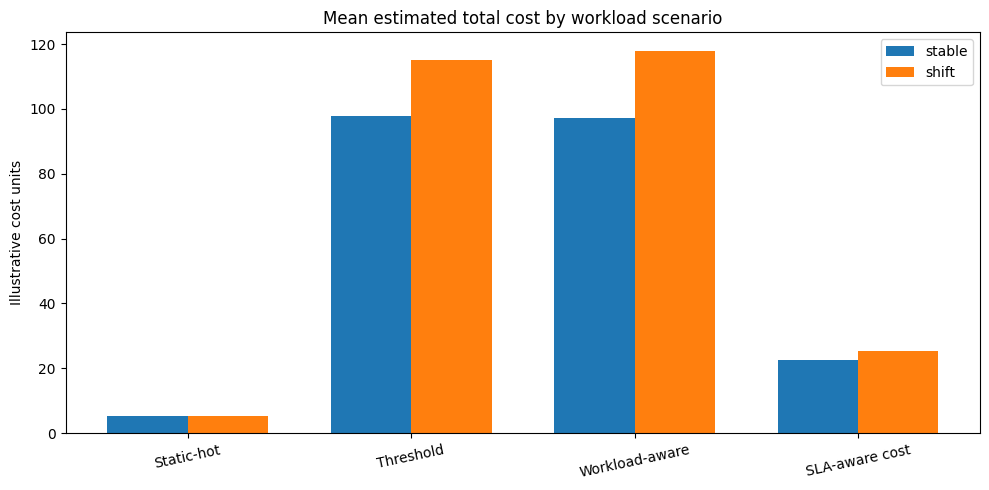

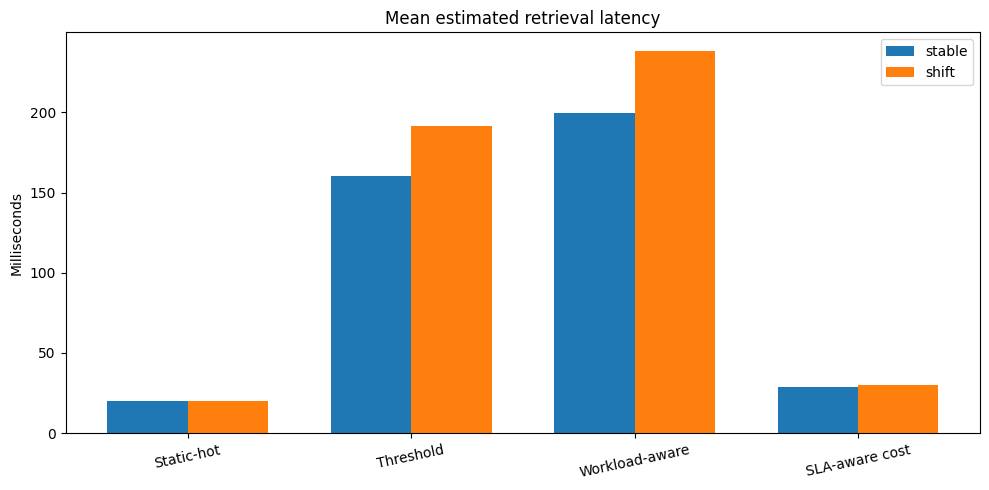

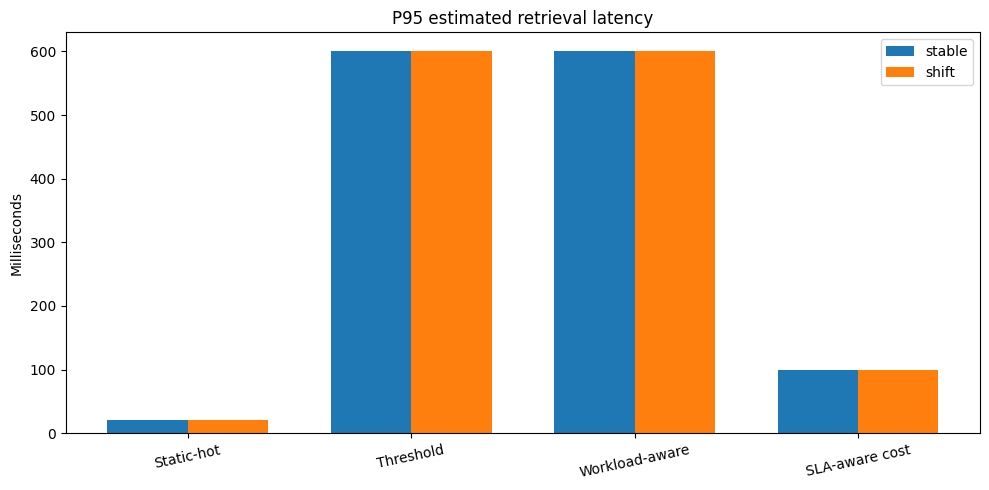

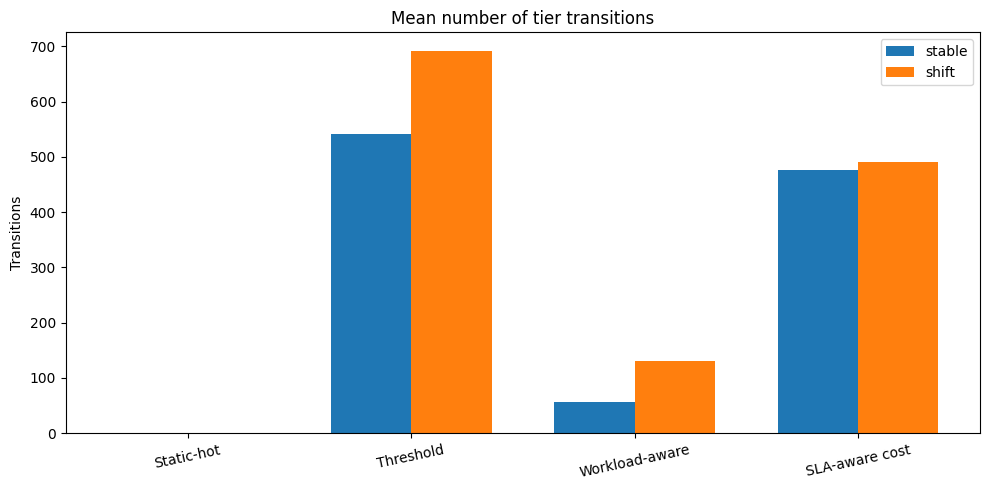

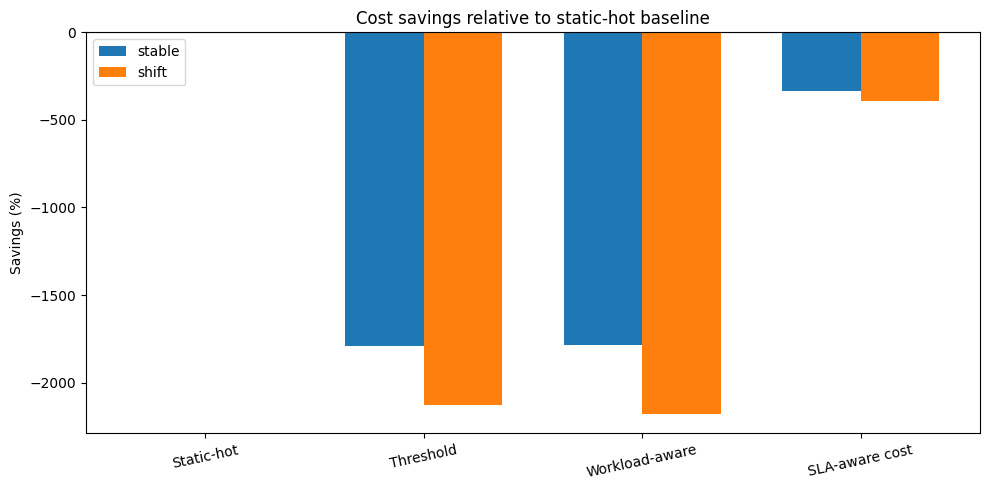

In [23]:
def plot_metric(metric, title, ylabel):
    plot_df = results_df.groupby(["scenario", "policy"])[metric].mean().reset_index()
    scenarios = ["stable", "shift"]
    policies = list(POLICIES.keys())
    x = np.arange(len(policies))
    width = 0.36
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, scenario in enumerate(scenarios):
        vals = [
            plot_df[(plot_df["scenario"] == scenario) & (plot_df["policy"] == p)][metric].iloc[0]
            for p in policies
        ]
        ax.bar(x + (i - 0.5) * width, vals, width, label=scenario)
    ax.set_xticks(x)
    ax.set_xticklabels(policies, rotation=12)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend()
    plt.tight_layout()
    plt.show()

plot_metric("total_estimated_cost", "Mean estimated total cost by workload scenario", "Illustrative cost units")
plot_metric("mean_estimated_latency_ms", "Mean estimated retrieval latency", "Milliseconds")
plot_metric("p95_estimated_latency_ms", "P95 estimated retrieval latency", "Milliseconds")
plot_metric("tier_transitions", "Mean number of tier transitions", "Transitions")
# Savings lives in `comparison`, not `results_df`; plot it from the correct DataFrame.
savings_plot_df = comparison.groupby(["scenario", "policy"])["cost_savings_percent_vs_static"].mean().reset_index()
scenarios = ["stable", "shift"]
policies = list(POLICIES.keys())
x = np.arange(len(policies))
width = 0.36
fig, ax = plt.subplots(figsize=(10, 5))
for i, scenario in enumerate(scenarios):
    vals = [
        savings_plot_df.loc[
            (savings_plot_df["scenario"] == scenario) &
            (savings_plot_df["policy"] == policy),
            "cost_savings_percent_vs_static"
        ].iloc[0]
        for policy in policies
    ]
    ax.bar(x + (i - 0.5) * width, vals, width, label=scenario)
ax.set_xticks(x)
ax.set_xticklabels(policies, rotation=12)
ax.set_ylabel("Savings (%)")
ax.set_title("Cost savings relative to static-hot baseline")
ax.axhline(0, linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()

## 10. Sensitivity analysis

The workload-aware policy's decisions depend on thresholds, tier prices, and migration charges. This small sensitivity analysis varies the migration cost per GB and reruns the shifting workload for one seed. Extend it with multiple values and seeds for final reporting.

,migration_cost_per_gb,policy,total_estimated_cost,tier_transitions,p95_estimated_latency_ms
0,0.0000,Static-hot,5.1412,0,20.0
1,0.0000,Threshold,104.3074,688,600.0
2,0.0000,Workload-aware,112.3155,126,600.0
3,0.0000,SLA-aware cost,22.0644,496,100.0
4,0.0025,Static-hot,5.1412,0,20.0
5,0.0025,Threshold,105.1669,688,600.0
6,0.0025,Workload-aware,112.4429,126,600.0
7,0.0025,SLA-aware cost,22.6858,496,100.0
8,0.0050,Static-hot,5.1412,0,20.0
9,0.0050,Threshold,106.0265,688,600.0


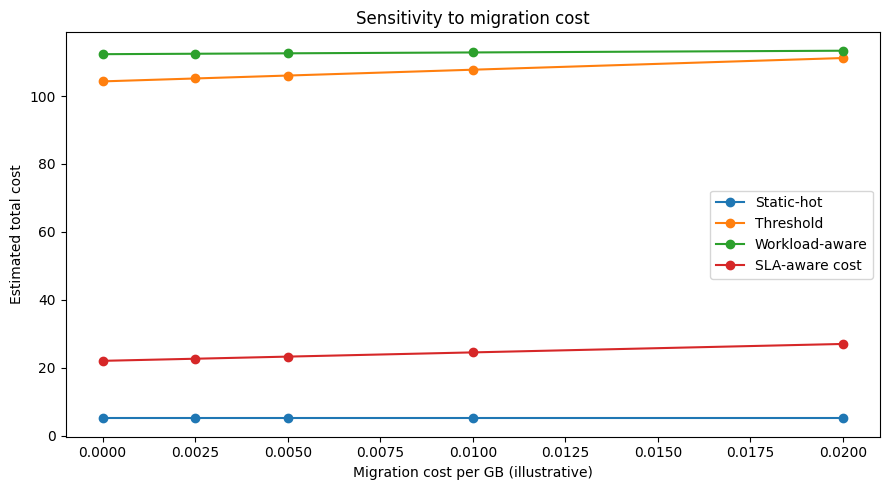

In [24]:
sensitivity_rows = []
sensitivity_seed = RANDOM_SEEDS[0]
sensitivity_trace = generate_workload("shift", seed=sensitivity_seed)

for migration_rate in [0.0, 0.0025, 0.005, 0.01, 0.02]:
    for policy_name, policy_fn in POLICIES.items():
        r, _ = simulate_policy(
            sensitivity_trace, policy_fn, policy_name,
            migration_cost_per_gb=migration_rate
        )
        sensitivity_rows.append({
            "migration_cost_per_gb": migration_rate,
            "policy": policy_name,
            "total_estimated_cost": r["total_estimated_cost"],
            "tier_transitions": r["tier_transitions"],
            "p95_estimated_latency_ms": r["p95_estimated_latency_ms"],
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df.round(4))
fig, ax = plt.subplots(figsize=(9, 5))
for policy_name in POLICIES:
    subset = sensitivity_df[sensitivity_df["policy"] == policy_name]
    ax.plot(subset["migration_cost_per_gb"], subset["total_estimated_cost"], marker="o", label=policy_name)
ax.set_xlabel("Migration cost per GB (illustrative)")
ax.set_ylabel("Estimated total cost")
ax.set_title("Sensitivity to migration cost")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Ablation study: isolate heuristic components

This section compares the full workload-aware heuristic with variants that remove one input/behavior at a time. It runs on both stable and shifting traces across the configured seeds. The variants are: full heuristic; no recency term; no recent-frequency term; and no hysteresis. All other simulator settings are held fixed.

**Interpretation guardrail:** this is an ablation of the current heuristic, not evidence that the method is globally optimal. Since the current policy does not enforce the latency target, the constraint is recorded as an outcome rather than treated as a hard guarantee.

,policy,total_estimated_cost,storage_cost,request_cost,retrieval_cost,migration_cost,transfer_cost,mean_estimated_latency_ms,p95_estimated_latency_ms,tier_transitions,bytes_moved_gb,read_events,latency_constraint_ms,meets_latency_constraint,scenario,seed,ablation_variant
0,Full heuristic,93.8803,1.2648,0.3595,92.1560,0.1000,0.0,198.0987,600.0,54,19.9973,30000,150.0,False,stable,11,Full heuristic
1,No recency,93.8803,1.2648,0.3595,92.1560,0.1000,0.0,198.0987,600.0,54,19.9973,30000,150.0,False,stable,11,No recency
2,No frequency,301.5794,1.0031,0.9000,299.6762,0.0000,0.0,600.0000,600.0,0,0.0000,30000,150.0,False,stable,11,No frequency
3,No hysteresis,79.6241,1.6905,0.2823,74.9807,2.6705,0.0,132.4800,600.0,972,534.1025,30000,150.0,False,stable,11,No hysteresis
4,Full heuristic,92.8168,1.4173,0.3642,90.8649,0.1703,0.0,201.6173,600.0,57,34.0529,30000,150.0,False,stable,22,Full heuristic
5,No recency,92.8168,1.4173,0.3642,90.8649,0.1703,0.0,201.6173,600.0,57,34.0529,30000,150.0,False,stable,22,No recency
6,No frequency,235.7492,1.0226,0.9000,233.8266,0.0000,0.0,600.0000,600.0,0,0.0000,30000,150.0,False,stable,22,No frequency
7,No hysteresis,76.8562,1.8204,0.2822,72.0111,2.7425,0.0,131.9060,600.0,1059,548.4947,30000,150.0,False,stable,22,No hysteresis


scenario ablation_variant total_estimated_cost          storage_cost  \
                                            mean      std         mean   
0    shift   Full heuristic             117.7537   8.7627       1.3945   
1    shift     No frequency             308.1663  54.7379       1.0086   
2    shift    No hysteresis              97.9827   7.3700       1.7942   
3    shift       No recency             117.7537   8.7627       1.3945   
4   stable   Full heuristic              97.3028   8.0148       1.3629   
5   stable     No frequency             307.4827  61.8228       1.0079   
6   stable    No hysteresis              82.1371   6.9915       1.7791   
7   stable       No recency              97.3028   8.0148       1.3629   

          request_cost         retrieval_cost           ...  \
      std         mean     std           mean      std  ...   
0  0.0722       0.4131  0.0077       115.6060   8.7040  ...   
1  0.0332       0.9000  0.0000       306.2577  54.7262  ...   
2  0.0675       0.3175  0.0079        92.7771   7.3069  ...   
3  0.0722       0.4131  0.0077       115.6060   8.7040  ...   
4  0.0762       0.3615  0.0023        95.4289   7.9747  ...   
5  0.0332       0.9000  0.0000       305.5749  61.8069  ...   
6  0.0818       0.2816  0.0008        77.3989   6.9528  ...   
7  0.0762       0.3615  0.0023        95.4289   7.9747  ...   

  mean_estimated_latency_ms         p95_estimated_latency_ms       \
                       mean     std                     mean  std   
0                  237.9679  5.7201                    600.0  0.0   
1                  600.0000  0.0000                    600.0  0.0   
2                  156.9872  6.2801                    600.0  0.0   
3                  237.9679  5.7201                    600.0  0.0   
4                  199.5525  1.7114                    600.0  0.0   
5                  600.0000  0.0000                    600.0  0.0   
6                  131.6495  0.6664                    600.0  0.0   
7                  199.5525  1.7114                    600.0  0.0   

  tier_transitions          bytes_moved_gb          meets_latency_constraint  \
              mean      std           mean      std                     mean   
0            129.8   5.2154        68.0161  11.5321                      0.0   
1              0.0   0.0000         0.0000   0.0000                      0.0   
2           1189.2  35.3864       618.8045  33.6181                      0.0   
3            129.8   5.2154        68.0161  11.5321                      0.0   
4             56.6   2.1909        29.8835   7.8795                      0.0   
5              0.0   0.0000         0.0000   0.0000                      0.0   
6           1025.6  34.5803       535.4711   8.8397                      0.0   
7             56.6   2.1909        29.8835   7.8795                      0.0   

        
   std  
0  0.0  
1  0.0  
2  0.0  
3  0.0  
4  0.0  
5  0.0  
6  0.0  
7  0.0  

[8 rows x 22 columns]

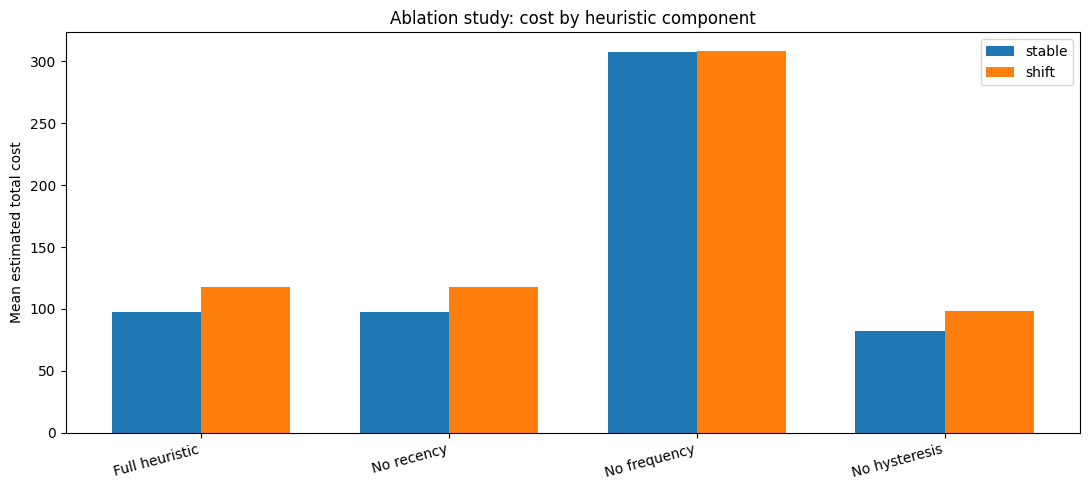

In [25]:
def make_ablated_policy(use_frequency=True, use_recency=True, hysteresis=True):
    """Create a policy variant with one or more heuristic components disabled."""
    def policy(features, current_tiers=None, **kwargs):
        current_tiers = current_tiers or {}
        out = {}
        for r in features.itertuples(index=False):
            frequency_term = np.log1p(r.recent_reads) if use_frequency else 0.0
            recency_term = 0.002 * np.log1p(r.recency_events) if use_recency else 0.0
            score = frequency_term - recency_term
            if score >= 2.8:
                proposed = "hot"
            elif score >= 1.1:
                proposed = "cool"
            else:
                proposed = "cold"
            old = current_tiers.get(r.object_id)
            if hysteresis and old is not None and proposed != old:
                if abs(TIER_ORDER[old] - TIER_ORDER[proposed]) == 1:
                    proposed = old
            out[r.object_id] = proposed
        return out
    return policy

ABLATION_VARIANTS = {
    "Full heuristic": make_ablated_policy(True, True, True),
    "No recency": make_ablated_policy(True, False, True),
    "No frequency": make_ablated_policy(False, True, True),
    "No hysteresis": make_ablated_policy(True, True, False),
}

ablation_rows = []
for scenario in ["stable", "shift"]:
    for seed in RANDOM_SEEDS:
        ablation_trace = generate_workload(scenario=scenario, seed=seed)
        for variant_name, variant_fn in ABLATION_VARIANTS.items():
            result, _ = simulate_policy(ablation_trace, variant_fn, variant_name)
            result["scenario"] = scenario
            result["seed"] = seed
            result["ablation_variant"] = variant_name
            ablation_rows.append(result)

ablation_df = pd.DataFrame(ablation_rows)
ablation_metrics = ["total_estimated_cost", "storage_cost", "request_cost", "retrieval_cost", "migration_cost", "mean_estimated_latency_ms", "p95_estimated_latency_ms", "tier_transitions", "bytes_moved_gb", "meets_latency_constraint"]
ablation_summary = ablation_df.groupby(["scenario", "ablation_variant"])[ablation_metrics].agg(["mean", "std"]).reset_index()
display(ablation_df.head(8).round(4))
display(ablation_summary.round(4))

fig, ax = plt.subplots(figsize=(11, 5))
plot_ablation = ablation_df.groupby(["scenario", "ablation_variant"])["total_estimated_cost"].mean().reset_index()
variants = list(ABLATION_VARIANTS.keys())
x = np.arange(len(variants))
width = 0.36
for i, scenario in enumerate(["stable", "shift"]):
    vals = [plot_ablation[(plot_ablation.scenario == scenario) & (plot_ablation.ablation_variant == v)]["total_estimated_cost"].iloc[0] for v in variants]
    ax.bar(x + (i - 0.5) * width, vals, width, label=scenario)
ax.set_xticks(x)
ax.set_xticklabels(variants, rotation=15, ha="right")
ax.set_ylabel("Mean estimated total cost")
ax.set_title("Ablation study: cost by heuristic component")
ax.legend()
plt.tight_layout()
plt.show()


## 12. Automated tests and invariants

These tests check structural properties of the implementation, not whether the model perfectly represents a commercial cloud provider. They are intended to catch common mistakes before interpreting results.

In [26]:
def run_tests():
    # Trace reproducibility and schema
    a = generate_workload("stable", n_objects=40, n_events=500, seed=123)
    b = generate_workload("stable", n_objects=40, n_events=500, seed=123)
    assert a.equals(b), "Same seed should reproduce the same trace"
    assert validate_trace(a)

    # Feature extraction should not include events at or after the boundary.
    f = extract_features(a, decision_end=100, window_events=50)
    assert set(f.columns) == {"object_id", "object_size_gb", "recent_reads", "recency_events"}
    assert (f["recent_reads"] >= 0).all()

    # Policies should assign valid tiers to all objects.
    for policy in POLICIES.values():
        assignments = policy(f, {})
        assert set(assignments.keys()) == set(f["object_id"])
        assert set(assignments.values()).issubset(set(TIERS.keys()))

    # Simulation outputs should be finite and nonnegative for costs and counts.
    for policy_name, policy_fn in POLICIES.items():
        result, _ = simulate_policy(a, policy_fn, policy_name, decision_interval=100)
        for key in ["total_estimated_cost", "storage_cost", "request_cost",
                    "retrieval_cost", "migration_cost", "transfer_cost"]:
            assert np.isfinite(result[key]) and result[key] >= 0, (key, result[key])
        assert result["tier_transitions"] >= 0
        assert result["read_events"] == len(a)

    # SLA-aware policy must never assign the modeled-infeasible cold tier.
    sla_assignments = sla_aware_cost_policy(f, {})
    assert set(sla_assignments.values()).issubset({"hot", "cool"})
    assert max(TIERS[t]["read_latency_ms"] for t in sla_assignments.values()) <= LATENCY_CONSTRAINT_MS

    # Decision causality: adding future rows must not change features computed at an earlier boundary.
    f_full = extract_features(a, decision_end=100, window_events=50)
    a_extended = pd.concat([a, a.iloc[-20:]], ignore_index=True)
    f_extended = extract_features(a_extended, decision_end=100, window_events=50)
    pd.testing.assert_frame_equal(f_full, f_extended)

    print("PASS: structural, numerical, causality, and SLA-policy tests")

run_tests()

PASS: structural, numerical, causality, and SLA-policy tests


## 13. Save all artifacts

This cell exports:
- full per-run results
- aggregated summary
- baseline-relative comparison
- sensitivity results
- interval-level migration records
- representative synthetic traces
- experiment configuration and a plain-text summary

All files are written to `/content/cloud_tiering_project/`. The final ZIP can be downloaded from Colab's file panel.

In [27]:
# Save tabular outputs
results_df.to_csv(OUTPUT_DIR / "per_run_results.csv", index=False)
summary.to_csv(OUTPUT_DIR / "aggregate_summary.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "baseline_comparison.csv", index=False)
sensitivity_df.to_csv(OUTPUT_DIR / "sensitivity_analysis.csv", index=False)
ablation_df.to_csv(OUTPUT_DIR / "ablation_results.csv", index=False)
ablation_summary.to_csv(OUTPUT_DIR / "ablation_summary.csv", index=False)
interval_df.to_csv(OUTPUT_DIR / "interval_migration_records.csv", index=False)

# Save representative traces for reproducibility
generate_workload("stable", seed=RANDOM_SEEDS[0]).to_csv(OUTPUT_DIR / "sample_stable_trace.csv", index=False)
generate_workload("shift", seed=RANDOM_SEEDS[0]).to_csv(OUTPUT_DIR / "sample_shift_trace.csv", index=False)

config = {
    "project_title": "Workload-Aware Cloud Storage Tiering for Cost and Latency Optimization",
    "seed_for_demo": SEED,
    "random_seeds": RANDOM_SEEDS,
    "n_objects": N_OBJECTS,
    "n_events": N_EVENTS,
    "simulated_days": SIMULATED_DAYS,
    "decision_interval_events": DECISION_INTERVAL_EVENTS,
    "window_events": WINDOW_EVENTS,
    "tiers": TIERS,
    "migration_cost_per_gb_illustrative": MIGRATION_COST_PER_GB,
    "transfer_cost_per_gb_illustrative": TRANSFER_COST_PER_GB,
    "latency_constraint_ms_illustrative": LATENCY_CONSTRAINT_MS,
    "workload_type": "synthetic",
    "latency_type": "simulated tier-level estimate, not live-provider measurement",
    "ablation_variants": list(ABLATION_VARIANTS.keys()),
    "latency_constraint_enforced": False,
    "pricing_note": "Illustrative placeholder values; replace with documented provider/region/date pricing before final claims.",
}
with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

report_lines = [
    "Cloud Storage Tiering - Experiment Run Summary",
    f"Runs: {len(results_df)}",
    f"Scenarios: {sorted(results_df['scenario'].unique().tolist())}",
    f"Policies: {sorted(results_df['policy'].unique().tolist())}",
    "Important: synthetic workloads and illustrative tier prices are used by default.",
    f"Ablation rows: {len(ablation_df)}; ablation variants: {sorted(ablation_df['ablation_variant'].unique().tolist())}",
    "Estimated latency is tier-level simulation output, not live cloud-provider measurement.",
    "Validate pricing, assumptions, and the cost model before including results in a paper.",
]
(OUTPUT_DIR / "README_RESULTS.txt").write_text("\n".join(report_lines), encoding="utf-8")

# Create zip of project outputs
zip_path = Path("/content/cloud_tiering_project_outputs.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=str(Path("cloud_tiering_project") / path.relative_to(OUTPUT_DIR)))

print("Artifacts saved:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)
print("\nZIP:", zip_path)

Artifacts saved:
- README_RESULTS.txt
- ablation_results.csv
- ablation_summary.csv
- aggregate_summary.csv
- baseline_comparison.csv
- experiment_config.json
- interval_migration_records.csv
- per_run_results.csv
- sample_shift_trace.csv
- sample_stable_trace.csv
- sensitivity_analysis.csv

ZIP: /content/cloud_tiering_project_outputs.zip


## 14. Research-validity checklist before paper submission

- [ ] Verify the full text of the closest published tiering and forecasting methods; record their objectives, data, assumptions, and evaluation metrics.
- [ ] Replace illustrative tier prices with a dated, official provider pricing schedule and document region, request types, retrieval charges, minimum-duration fees, and migration/transfer treatment.
- [ ] Use a licensed public workload trace if feasible; document its origin, schema, cleaning, and limitations. Keep synthetic scenarios as controlled stress tests.
- [ ] Treat tier latency values as modeled assumptions unless actual measurements are collected. Do not call these values observed cloud latency.
- [ ] Evaluate all policies on the exact same trace, seeds, time horizon, and cost assumptions. Tune thresholds only on separate development traces.
- [ ] Report paired differences or confidence intervals across seeds; report SLA-feasible fraction, p95, total cost, cost components, transitions, and moved GB.
- [ ] The SLA-aware policy is only guaranteed feasible for the **configured model** because it excludes cold. Real systems may have other latency/availability constraints.
- [ ] Inspect the ablation table: if disabling a feature gives identical results, verify that feature affects decisions before interpreting its contribution.
- [ ] Do not claim novelty or superiority from this simulation alone. The contribution must be differentiated from close prior cost/latency-aware tiering work.
- [ ] Negative or mixed results are valid; explain them rather than forcing a winning claim.


## 15. Optional: download the results ZIP

After running the notebook, this cell prompts a download in Google Colab. If running outside Colab, the files remain in the output directory.

In [73]:
try:
    from google.colab import files
    files.download("/content/cloud_tiering_project_outputs.zip")
except Exception as exc:
    print("Colab download helper unavailable in this environment.")
    print("Find the ZIP at /content/cloud_tiering_project_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>